# Calibracao das probabilidades preditas pelos cinco algoritmos

Este notebook avalia a calibracao das probabilidades de obito preditas pelos cinco algoritmos sobre o teste de 2024, alem da capacidade de ordenacao e discriminacao ja avaliada nos notebooks anteriores desta fase.
Um modelo bem calibrado produz probabilidades que correspondem, na media, a frequencia observada de obito entre os casos com aquela probabilidade predita, o que e essencial se as probabilidades forem usadas diretamente para apoiar decisao clinica, e nao apenas para ordenar os casos por risco.
A calibracao e avaliada de duas formas complementares: pelo Brier Skill Score, que resume a qualidade das probabilidades num unico numero relativo a um modelo de referencia, e por curvas de calibracao, que mostram visualmente se as probabilidades preditas estao sistematicamente acima ou abaixo da frequencia observada ao longo da faixa de risco.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessing.py`, e cria os diretorios de saida usados ao longo do notebook.
A tabela de calibracao por decil e salva em `analysis/results_avaliacao/`, e os graficos de curvas de calibracao sao salvos em `analysis/plots/avaliacao/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessing

DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_avaliacao"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "avaliacao"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
NUMERO_DECIS = 10

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real salvos pela fase de modelagem para o teste de 2024, e calcula a prevalencia observada de obito nesse conjunto.
Essa prevalencia e usada na secao seguinte como a probabilidade constante do modelo de referencia do Brier Skill Score.

In [2]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet")
    for algoritmo in ALGORITMOS
}

alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
prevalencia_obito_teste2024 = alvo_real_teste2024.mean()

prevalencia_obito_teste2024

np.float64(0.05228758169934641)

Calcula o Brier Score do modelo de referencia, que sempre prediz a prevalencia observada de obito para todos os casos, e o Brier Score de cada um dos cinco algoritmos, usando `avaliar_predicoes` de `utils/preprocessing.py`.
O Brier Skill Score de cada algoritmo e definido como `1 - brier_modelo / brier_referencia`, de forma que um BSS positivo indica que o algoritmo produz probabilidades mais proximas da frequencia observada do que a referencia ingenua, um BSS igual a zero indica desempenho equivalente ao da referencia, e um BSS negativo indica que o algoritmo e pior que simplesmente prever a prevalencia para todos os casos.

In [3]:
probabilidade_referencia = np.full(len(alvo_real_teste2024), prevalencia_obito_teste2024)
brier_referencia = brier_score_loss(alvo_real_teste2024, probabilidade_referencia)

linhas_bss = []
for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    metricas = preprocessing.avaliar_predicoes(alvo_real_teste2024, probabilidade_predita)
    brier_skill_score = 1 - metricas["brier_score"] / brier_referencia
    linhas_bss.append(
        {
            "algoritmo": algoritmo,
            "brier_score": metricas["brier_score"],
            "brier_score_referencia": brier_referencia,
            "brier_skill_score": brier_skill_score,
        }
    )

tabela_bss = pd.DataFrame(linhas_bss).sort_values("brier_skill_score", ascending=False).reset_index(drop=True)
tabela_bss.to_csv(DIRETORIO_RESULTADOS_ANALISE / "brier_skill_score_teste2024.csv", index=False)
tabela_bss

,algoritmo,brier_score,brier_score_referencia,brier_skill_score
0,random_forest,0.072640,0.049554,-0.465888
1,lightgbm,0.140349,0.049554,-1.832262
2,xgboost,0.189623,0.049554,-2.826632
3,arvore_decisao,0.239224,0.049554,-3.827575
4,regressao_logistica,0.239320,0.049554,-3.829525


Constroi, para cada algoritmo, a tabela de calibracao por decil de probabilidade predita.
Os casos do teste de 2024 sao divididos em decis pela propria probabilidade predita de cada algoritmo, usando `pd.qcut`, e para cada decil sao calculados o numero de casos, a probabilidade media predita e a fracao observada de obito.
Quando um algoritmo produz poucos valores distintos de probabilidade, como a Arvore de Decisao, decis adjacentes podem ter a mesma fronteira e serem automaticamente combinados por `pd.qcut`, o que resulta em menos de dez decis efetivos para esse algoritmo.

In [4]:
tabelas_calibracao_por_decil = []
for algoritmo in ALGORITMOS:
    tabela_algoritmo = predicoes_teste2024[algoritmo].copy()
    tabela_algoritmo["decil"] = pd.qcut(
        tabela_algoritmo["probabilidade_predita"], NUMERO_DECIS, labels=False, duplicates="drop"
    )

    resumo_decis = (
        tabela_algoritmo.groupby("decil")
        .agg(
            numero_casos=("obito", "size"),
            probabilidade_media_predita=("probabilidade_predita", "mean"),
            fracao_observada_obito=("obito", "mean"),
        )
        .reset_index()
    )
    resumo_decis["decil"] = resumo_decis["decil"] + 1
    resumo_decis["algoritmo"] = algoritmo
    resumo_decis["numero_decis_efetivo"] = resumo_decis["decil"].max()

    tabelas_calibracao_por_decil.append(resumo_decis)

tabela_calibracao_por_decil = pd.concat(tabelas_calibracao_por_decil, ignore_index=True)[
    ["algoritmo", "decil", "numero_decis_efetivo", "numero_casos", "probabilidade_media_predita", "fracao_observada_obito"]
]

tabela_calibracao_por_decil.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "calibracao_por_decil.csv", index=False
)
tabela_calibracao_por_decil

,algoritmo,decil,numero_decis_efetivo,numero_casos,probabilidade_media_predita,fracao_observada_obito
0,regressao_logistica,1,10,398,0.179032,0.005025
1,regressao_logistica,2,10,398,0.261684,0.005025
2,regressao_logistica,3,10,398,0.315778,0.015075
3,regressao_logistica,4,10,397,0.365274,0.007557
4,regressao_logistica,5,10,398,0.420317,0.027638
5,regressao_logistica,6,10,398,0.478689,0.030151
6,regressao_logistica,7,10,397,0.541197,0.037783
7,regressao_logistica,8,10,398,0.616020,0.050251
8,regressao_logistica,9,10,398,0.707024,0.133166
9,regressao_logistica,10,10,398,0.816509,0.211055


Gera as curvas de calibracao dos cinco algoritmos num unico grafico, usando `calibration_curve` com decis de probabilidade predita.
A diagonal pontilhada representa a calibracao perfeita, em que a probabilidade predita e igual a fracao observada de obito, e curvas acima dessa diagonal indicam subestimacao do risco, enquanto curvas abaixo indicam sobreestimacao.
O grafico e salvo em `analysis/plots/avaliacao/curvas_calibracao_5_algoritmos.png`.

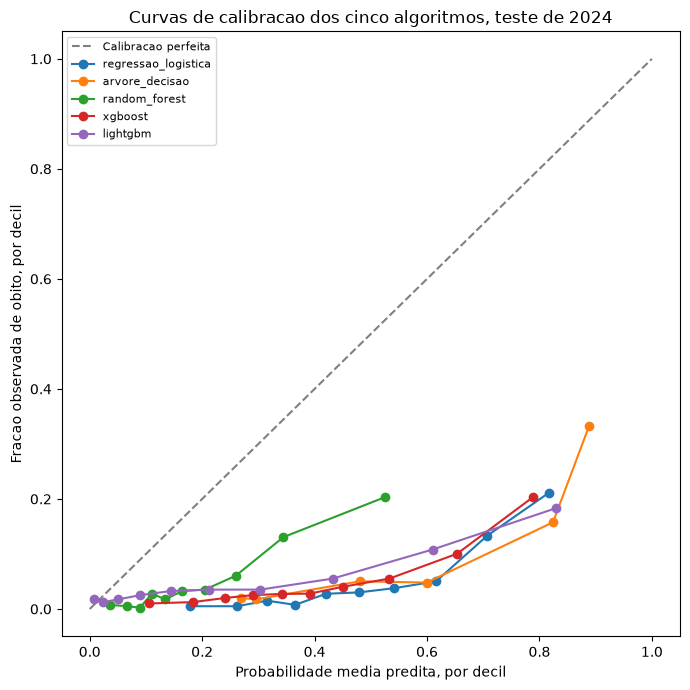

In [5]:
figura, eixo = plt.subplots(figsize=(7, 7))
eixo.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibracao perfeita")

for algoritmo in ALGORITMOS:
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    fracao_observada, probabilidade_media = calibration_curve(
        alvo_real_teste2024, probabilidade_predita, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    eixo.plot(probabilidade_media, fracao_observada, marker="o", label=algoritmo)

eixo.set_xlabel("Probabilidade media predita, por decil")
eixo.set_ylabel("Fracao observada de obito, por decil")
eixo.set_title("Curvas de calibracao dos cinco algoritmos, teste de 2024")
eixo.legend(loc="upper left", fontsize=8)
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_5_algoritmos.png", dpi=150)
plt.show()

Gera o mesmo conjunto de curvas de calibracao em paineis separados por algoritmo, com a mesma escala de eixos para os cinco paineis, o que facilita a leitura individual de cada curva sem a sobreposicao visual do grafico unico anterior.
O grafico e salvo em `analysis/plots/avaliacao/curvas_calibracao_por_algoritmo.png`.

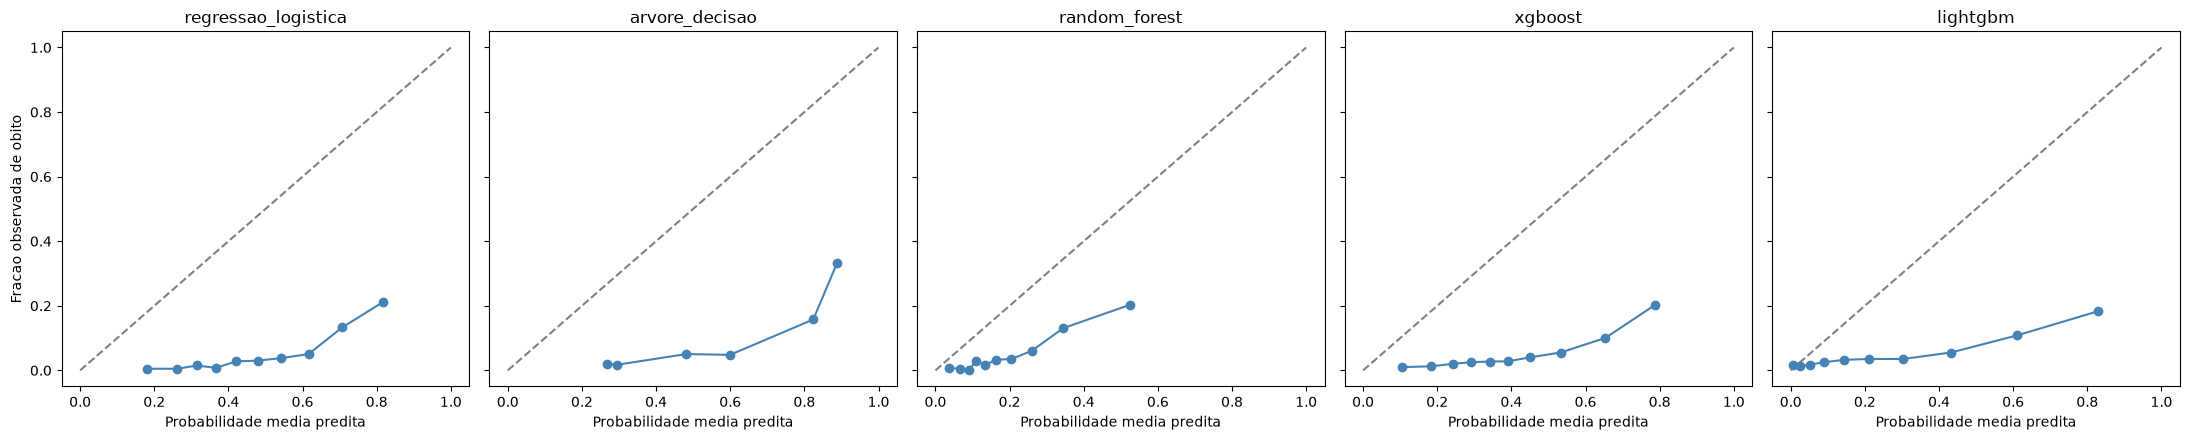

In [6]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(22, 4.5), sharex=True, sharey=True)

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    probabilidade_predita = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    fracao_observada, probabilidade_media = calibration_curve(
        alvo_real_teste2024, probabilidade_predita, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    eixo_atual.plot([0, 1], [0, 1], linestyle="--", color="gray")
    eixo_atual.plot(probabilidade_media, fracao_observada, marker="o", color="steelblue")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Probabilidade media predita")

eixos[0].set_ylabel("Fracao observada de obito")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_por_algoritmo.png", dpi=150)
plt.show()

## Sintese dos achados

O Brier Skill Score dos cinco algoritmos e negativo em todos os casos, de -0,466 para o Random Forest a -3,830 para a Regressao Logistica, o que significa que nenhum dos cinco algoritmos supera, em Brier Score absoluto, o modelo de referencia trivial que sempre prediz a prevalencia observada de obito, 5,23 por cento, para todos os casos.
Essa e uma consequencia direta da baixa prevalencia de obito combinada com o objetivo de discriminar os casos de maior risco, e nao uma falha isolada de um algoritmo especifico.
A referencia trivial ja acerta a maioria das observacoes ao prever um numero pequeno para quase todos os casos, que de fato nao evoluem a obito, enquanto qualquer modelo que atribua probabilidades altas aos casos de maior risco paga um custo em erro quadratico sempre que esse risco elevado nao se concretiza, o que e frequente mesmo nos decis de maior risco, ja que a prevalencia de obito permanece baixa mesmo entre os casos mais graves.
O Random Forest tem o Brier Skill Score menos negativo entre os cinco algoritmos, o que confirma, em termos relativos ao modelo de referencia, a leitura ja indicada pelo Brier Score absoluto na fase de modelagem.
A tabela por decil mostra a razao concreta dessa vantagem relativa: no decil de maior risco, a probabilidade media predita pelo Random Forest e 0,526 contra uma fracao observada de obito de 0,204, uma distancia bem menor do que a da Regressao Logistica, cujo decil de maior risco tem probabilidade media de 0,817 contra uma fracao observada de obito de 0,211.
Regressao Logistica e o algoritmo com a melhor capacidade de discriminacao entre os cinco, com a maior AUPRC e o maior ROC-AUC pontuais no teste de 2024, ja documentados no notebook anterior desta fase, mas tambem o algoritmo com o Brier Skill Score mais negativo entre os cinco, -3,830, praticamente empatado com o da Arvore de Decisao, -3,828, o algoritmo com a pior discriminacao do grupo.
Esse contraste mostra de forma particularmente clara que calibracao e capacidade de discriminacao sao propriedades distintas de um mesmo algoritmo, e que o melhor discriminador nao e, nem de longe, o algoritmo com as probabilidades absolutas mais proximas da frequencia real.
O deslocamento acentuado da Regressao Logistica para probabilidades muito acima da frequencia real, visivel em quase todos os decis na curva de calibracao, e consequencia direta do uso de `class_weight="balanced"`, que melhora a discriminacao entre as classes mas piora sistematicamente a correspondencia entre a probabilidade predita e a frequencia real.
O LightGBM tem o segundo Brier Skill Score menos negativo entre os cinco, -1,832, com padrao de calibracao tambem deslocado para cima em relacao a diagonal de calibracao perfeita ao longo de quase toda a faixa de risco, embora de forma menos extrema do que a Regressao Logistica.
O XGBoost ocupa uma posicao intermediaria de calibracao, com Brier Skill Score de -2,827, pior do que o do Random Forest e do LightGBM, mas ainda menos negativo do que o da Arvore de Decisao e o da Regressao Logistica.
A Arvore de Decisao tem poucos valores distintos de probabilidade predita, o que reduz a seis o numero de decis efetivos nessa analise, dos quais o ultimo concentra apenas 3 casos e deve ser lido com cautela.
No penultimo decil, com 660 casos, a fracao observada de obito e de apenas 0,158 apesar de uma probabilidade media predita de 0,824, a maior distancia entre probabilidade predita e frequencia observada entre todos os algoritmos e decis com um numero razoavel de casos analisados aqui.
Em conjunto, estes resultados indicam que a boa capacidade de ordenacao de risco dos cinco algoritmos, ja documentada pela AUPRC e pelo ROC-AUC na fase de modelagem, nao se traduz em probabilidades absolutas bem calibradas em relacao a uma referencia ingenua, e que o Random Forest, apesar disso, e o algoritmo cujas probabilidades mais se aproximam da frequencia observada de obito entre os cinco avaliados.

## Recalibracao por Platt scaling das probabilidades

O diagnostico anterior mostra que os cinco algoritmos tem Brier Skill Score negativo no teste de 2024, uma consequencia direta do uso de class_weight="balanced" ou scale_pos_weight no treino, que melhora a capacidade de ordenar os casos por risco mas desloca as probabilidades preditas para valores sistematicamente acima da frequencia observada de obito.
Esta secao corrige esse problema por recalibracao sigmoide, tambem chamada de Platt scaling, uma transformacao que ajusta o nivel absoluto das probabilidades preditas para que corresponda a frequencia observada de obito, sem alterar de forma relevante a ordenacao dos casos por risco.

O modelo final de cada algoritmo, ja ajustado em todo o treino de 2020 a 2023 e salvo em output/modelos/{algoritmo}.joblib, nao e reajustado nesta secao.
Ele continua sendo o unico modelo usado para gerar a probabilidade bruta de risco no teste de 2024 e na validacao externa de 2025, e essas probabilidades brutas ja estao salvas pela fase de modelagem e sao reaproveitadas aqui, sem nova previsao.
A funcao de correcao de calibracao e aprendida separadamente, numa reserva temporal dedicada a esse unico fim.
Um clone do pipeline de cada algoritmo e ajustado apenas no periodo de 2020 a 2022, e suas probabilidades preditas para o ano de 2023, que nao participou desse ajuste, sao comparadas ao desfecho real de obito em 2023 por uma regressao logistica unidimensional.
Essa regressao logistica, ajustada com a probabilidade predita de 2023 como unica variavel de entrada e o desfecho real de obito em 2023 como alvo, e a funcao de correcao de calibracao de cada algoritmo, tambem chamada de Platt scaling, e e aplicada diretamente sobre as probabilidades brutas do modelo final, treinado em todo o periodo de 2020 a 2023, para o teste de 2024 e para a validacao externa de 2025.
Como essa correcao ajusta o nivel absoluto das probabilidades por uma funcao sigmoide suave, com apenas dois parametros ajustados, ela preserva bem a ordem relativa dos casos mesmo numa reserva de calibracao pequena e com desfecho raro, como e o caso do ano de 2023 usado aqui, com 2441 casos e aproximadamente 109 obitos.

A partir desta secao, os artefatos com o sufixo _calibrado, tanto as predicoes de probabilidade quanto a funcao de correcao salva, passam a ser a estimativa recomendada de risco real de obito para qualquer uso futuro do estudo que dependa do valor absoluto da probabilidade predita, como eventual apoio a decisao clinica.
Os artefatos sem esse sufixo continuam validos para qualquer analise baseada na ordenacao dos casos, como a importancia de variaveis ou a comparacao de AUPRC entre subgrupos, por serem os mesmos artefatos ja usados nas demais fases deste estudo.
Para gerar uma probabilidade recalibrada em qualquer uso futuro do estudo, sao necessarios dois passos em sequencia.
Primeiro, gerar a probabilidade bruta de risco com o modelo final salvo em output/modelos/{algoritmo}.joblib.
Depois, aplicar a funcao de correcao salva em output/modelos/{algoritmo}_calibrado.joblib sobre essa probabilidade bruta, remodelada em formato de coluna, chamando seu metodo predict_proba e usando a segunda coluna do resultado, que corresponde a probabilidade da classe obito.

Carrega as predicoes de probabilidade bruta e o alvo real do modelo final para a validacao externa de 2025, ja salvas pela fase de modelagem, que ainda nao haviam sido usadas neste notebook.
Essas probabilidades serao usadas tanto para receber a correcao de calibracao aprendida nesta secao quanto para a tabela de comparacao antes e depois especifica da validacao externa de 2025, mais adiante.

In [7]:
predicoes_val2025_nao_calibrado = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025.parquet")
    for algoritmo in ALGORITMOS
}

alvo_real_val2025 = predicoes_val2025_nao_calibrado[ALGORITMOS[0]]["obito"].to_numpy()
prevalencia_obito_val2025 = alvo_real_val2025.mean()
probabilidade_referencia_val2025 = np.full(len(alvo_real_val2025), prevalencia_obito_val2025)
brier_referencia_val2025 = brier_score_loss(alvo_real_val2025, probabilidade_referencia_val2025)

prevalencia_obito_val2025

np.float64(0.02746066029003394)

Importa clone do scikit-learn, carrega apenas os preditores e o alvo do treino completo de 2020 a 2023, construidos pelo pipeline de dados, e reconstroi os mesmos tres folds de validacao temporal por expanding window usados na fase de modelagem.
O ultimo desses tres folds, o unico cuja particao de validacao e o ano de 2023, fornece exatamente a divisao necessaria para esta secao.
Seus indices de treino correspondem aos anos de 2020 a 2022, e seus indices de validacao correspondem ao ano de 2023, por isso sao reutilizados diretamente em vez de refazer o filtro por ano a partir de chik_treated.parquet.

In [8]:
import joblib
from sklearn.base import clone

DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_MODELOS = PROJECT_ROOT / "output" / "modelos"

X_train = pd.read_parquet(DIRETORIO_FEATURES / "X_train.parquet")
y_train = pd.read_parquet(DIRETORIO_FEATURES / "y_train.parquet")[preprocessing.COLUNA_ALVO]

folds_expanding_window = preprocessing.construir_folds_expanding_window(
    PROJECT_ROOT, tamanho_treino=len(X_train)
)
indices_treino_2020_2022, indices_validacao_2023 = folds_expanding_window[-1]

len(indices_treino_2020_2022), len(indices_validacao_2023)

(4730, 2441)

Para cada um dos cinco algoritmos, carrega o pipeline final ja ajustado em todo o treino de 2020 a 2023 e clona apenas a sua estrutura e hiperparametros, sem reaproveitar nenhum peso ja ajustado.
Esse clone e ajustado apenas nos indices de 2020 a 2022, e usado para prever a probabilidade de obito nos casos de 2023, que nao participaram desse ajuste.
Essas probabilidades previstas em 2023 e o desfecho real de obito em 2023 sao usados para ajustar uma unica regressao logistica unidimensional por algoritmo, a funcao de correcao de calibracao por Platt scaling, que depois e aplicada diretamente sobre as probabilidades brutas ja existentes do modelo final para o teste de 2024 e para a validacao externa de 2025.
O modelo final usado para gerar essas probabilidades brutas e sempre o mesmo pipeline treinado em todo o periodo de 2020 a 2023, nunca o clone menor ajustado so em 2020 a 2022, que serve apenas para aprender a funcao de correcao.
As predicoes recalibradas dos dois anos e a funcao de correcao ajustada sao salvas em output/metricas/ e output/modelos/ com o sufixo _calibrado, reutilizando salvar_predicoes e salvar_modelo de utils/preprocessing.py.

In [9]:
from sklearn.linear_model import LogisticRegression

recalibradores_platt = {}
predicoes_teste2024_calibrado = {}
predicoes_val2025_calibrado = {}

for algoritmo in ALGORITMOS:
    modelo_final_ajustado = joblib.load(DIRETORIO_MODELOS / f"{algoritmo}.joblib")
    modelo_para_calibracao = clone(modelo_final_ajustado)
    modelo_para_calibracao.fit(
        X_train.iloc[indices_treino_2020_2022], y_train.iloc[indices_treino_2020_2022]
    )

    probabilidade_2023 = modelo_para_calibracao.predict_proba(
        X_train.iloc[indices_validacao_2023]
    )[:, 1]
    alvo_real_2023 = y_train.iloc[indices_validacao_2023].to_numpy()

    recalibrador_platt = LogisticRegression()
    recalibrador_platt.fit(probabilidade_2023.reshape(-1, 1), alvo_real_2023)

    probabilidade_teste2024_calibrada = recalibrador_platt.predict_proba(
        predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy().reshape(-1, 1)
    )[:, 1]
    probabilidade_val2025_calibrada = recalibrador_platt.predict_proba(
        predicoes_val2025_nao_calibrado[algoritmo]["probabilidade_predita"].to_numpy().reshape(-1, 1)
    )[:, 1]

    preprocessing.salvar_predicoes(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024_calibrado.parquet",
        probabilidade_teste2024_calibrada,
        alvo_real_teste2024,
    )
    preprocessing.salvar_predicoes(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025_calibrado.parquet",
        probabilidade_val2025_calibrada,
        alvo_real_val2025,
    )
    preprocessing.salvar_modelo(
        DIRETORIO_MODELOS / f"{algoritmo}_calibrado.joblib", recalibrador_platt
    )

    recalibradores_platt[algoritmo] = recalibrador_platt
    predicoes_teste2024_calibrado[algoritmo] = pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024_calibrado.parquet"
    )
    predicoes_val2025_calibrado[algoritmo] = pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025_calibrado.parquet"
    )

list(recalibradores_platt.keys())

['regressao_logistica',
 'arvore_decisao',
 'random_forest',
 'xgboost',
 'lightgbm']

Recalcula AUPRC, ROC-AUC e Brier Score de cada algoritmo no teste de 2024 a partir das probabilidades recalibradas pela regressao logistica de Platt scaling, usando a mesma funcao avaliar_predicoes, e recalcula o Brier Skill Score com a mesma referencia trivial de prevalencia ja usada no diagnostico.
A tabela resultante coloca lado a lado os valores antes e depois da recalibracao para as quatro metricas, e substitui a tabela brier_skill_score_teste2024.csv gerada no diagnostico, que continha apenas os valores antes da recalibracao.

In [10]:
linhas_comparacao_calibracao = []
for algoritmo in ALGORITMOS:
    metricas_nao_calibrado = preprocessing.avaliar_predicoes(
        alvo_real_teste2024, predicoes_teste2024[algoritmo]["probabilidade_predita"]
    )
    metricas_calibrado = preprocessing.avaliar_predicoes(
        alvo_real_teste2024, predicoes_teste2024_calibrado[algoritmo]["probabilidade_predita"]
    )

    linhas_comparacao_calibracao.append(
        {
            "algoritmo": algoritmo,
            "auprc_nao_calibrado": metricas_nao_calibrado["auprc"],
            "auprc_calibrado": metricas_calibrado["auprc"],
            "roc_auc_nao_calibrado": metricas_nao_calibrado["roc_auc"],
            "roc_auc_calibrado": metricas_calibrado["roc_auc"],
            "brier_score_nao_calibrado": metricas_nao_calibrado["brier_score"],
            "brier_score_calibrado": metricas_calibrado["brier_score"],
            "brier_score_referencia": brier_referencia,
            "brier_skill_score_nao_calibrado": 1 - metricas_nao_calibrado["brier_score"] / brier_referencia,
            "brier_skill_score_calibrado": 1 - metricas_calibrado["brier_score"] / brier_referencia,
        }
    )

tabela_calibracao_antes_depois_teste2024 = (
    pd.DataFrame(linhas_comparacao_calibracao)
    .sort_values("brier_skill_score_calibrado", ascending=False)
    .reset_index(drop=True)
)
tabela_calibracao_antes_depois_teste2024.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "brier_skill_score_teste2024.csv", index=False
)
tabela_calibracao_antes_depois_teste2024

,algoritmo,auprc_nao_calibrado,auprc_calibrado,roc_auc_nao_calibrado,roc_auc_calibrado,brier_score_nao_calibrado,brier_score_calibrado,brier_score_referencia,brier_skill_score_nao_calibrado,brier_skill_score_calibrado
0,regressao_logistica,0.206604,0.206604,0.810633,0.810633,0.239320,0.045959,0.049554,-3.829525,0.072531
1,random_forest,0.187008,0.187008,0.804966,0.804966,0.072640,0.046079,0.049554,-0.465888,0.070113
2,xgboost,0.196245,0.196245,0.765930,0.765930,0.189623,0.046553,0.049554,-2.826632,0.060561
3,lightgbm,0.168298,0.168298,0.745586,0.745586,0.140349,0.047119,0.049554,-1.832262,0.049127
4,arvore_decisao,0.120433,0.120433,0.714876,0.714876,0.239224,0.047417,0.049554,-3.827575,0.043118


Repete a mesma comparacao antes e depois da recalibracao para a validacao externa de 2025, reaproveitando as predicoes nao calibradas e a referencia trivial desse ano, carregadas antes da secao de recalibracao por Platt scaling.
Esta tabela e complementar a anterior, pois confirma se a melhora de calibracao obtida no teste de 2024 se mantem num ano que nao participa nem do treino do modelo final nem do ajuste da regressao logistica de calibracao, e e salva separadamente em calibracao_antes_depois_val2025.csv.

In [11]:
linhas_comparacao_calibracao_val2025 = []
for algoritmo in ALGORITMOS:
    metricas_nao_calibrado = preprocessing.avaliar_predicoes(
        alvo_real_val2025, predicoes_val2025_nao_calibrado[algoritmo]["probabilidade_predita"]
    )
    metricas_calibrado = preprocessing.avaliar_predicoes(
        alvo_real_val2025, predicoes_val2025_calibrado[algoritmo]["probabilidade_predita"]
    )

    linhas_comparacao_calibracao_val2025.append(
        {
            "algoritmo": algoritmo,
            "auprc_nao_calibrado": metricas_nao_calibrado["auprc"],
            "auprc_calibrado": metricas_calibrado["auprc"],
            "roc_auc_nao_calibrado": metricas_nao_calibrado["roc_auc"],
            "roc_auc_calibrado": metricas_calibrado["roc_auc"],
            "brier_score_nao_calibrado": metricas_nao_calibrado["brier_score"],
            "brier_score_calibrado": metricas_calibrado["brier_score"],
            "brier_score_referencia": brier_referencia_val2025,
            "brier_skill_score_nao_calibrado": 1 - metricas_nao_calibrado["brier_score"] / brier_referencia_val2025,
            "brier_skill_score_calibrado": 1 - metricas_calibrado["brier_score"] / brier_referencia_val2025,
        }
    )

tabela_calibracao_antes_depois_val2025 = (
    pd.DataFrame(linhas_comparacao_calibracao_val2025)
    .sort_values("brier_skill_score_calibrado", ascending=False)
    .reset_index(drop=True)
)
tabela_calibracao_antes_depois_val2025.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "calibracao_antes_depois_val2025.csv", index=False
)
tabela_calibracao_antes_depois_val2025

,algoritmo,auprc_nao_calibrado,auprc_calibrado,roc_auc_nao_calibrado,roc_auc_calibrado,brier_score_nao_calibrado,brier_score_calibrado,brier_score_referencia,brier_skill_score_nao_calibrado,brier_skill_score_calibrado
0,regressao_logistica,0.136544,0.136544,0.817565,0.817565,0.243486,0.025958,0.026707,-8.117089,0.028046
1,random_forest,0.122927,0.122927,0.802052,0.802052,0.060460,0.026142,0.026707,-1.263857,0.021135
2,arvore_decisao,0.076631,0.076631,0.735123,0.735123,0.234581,0.026271,0.026707,-7.783639,0.016298
3,xgboost,0.115276,0.115276,0.763644,0.763644,0.181436,0.026700,0.026707,-5.793689,0.000239
4,lightgbm,0.113570,0.113570,0.747594,0.747594,0.128512,0.026794,0.026707,-3.811994,-0.003265


Gera, num painel com um grafico por algoritmo, as curvas de calibracao antes e depois da recalibracao por Platt scaling no teste de 2024, na mesma escala de eixos para os cinco paineis.
A curva antes da recalibracao e a mesma ja mostrada na secao de diagnostico, e a curva depois usa as probabilidades recalibradas desta secao, o que permite comparar visualmente, para cada algoritmo, o quanto a recalibracao aproximou a curva da diagonal de calibracao perfeita.

O grafico e salvo em analysis/plots/avaliacao/curvas_calibracao_antes_depois_recalibracao.png.

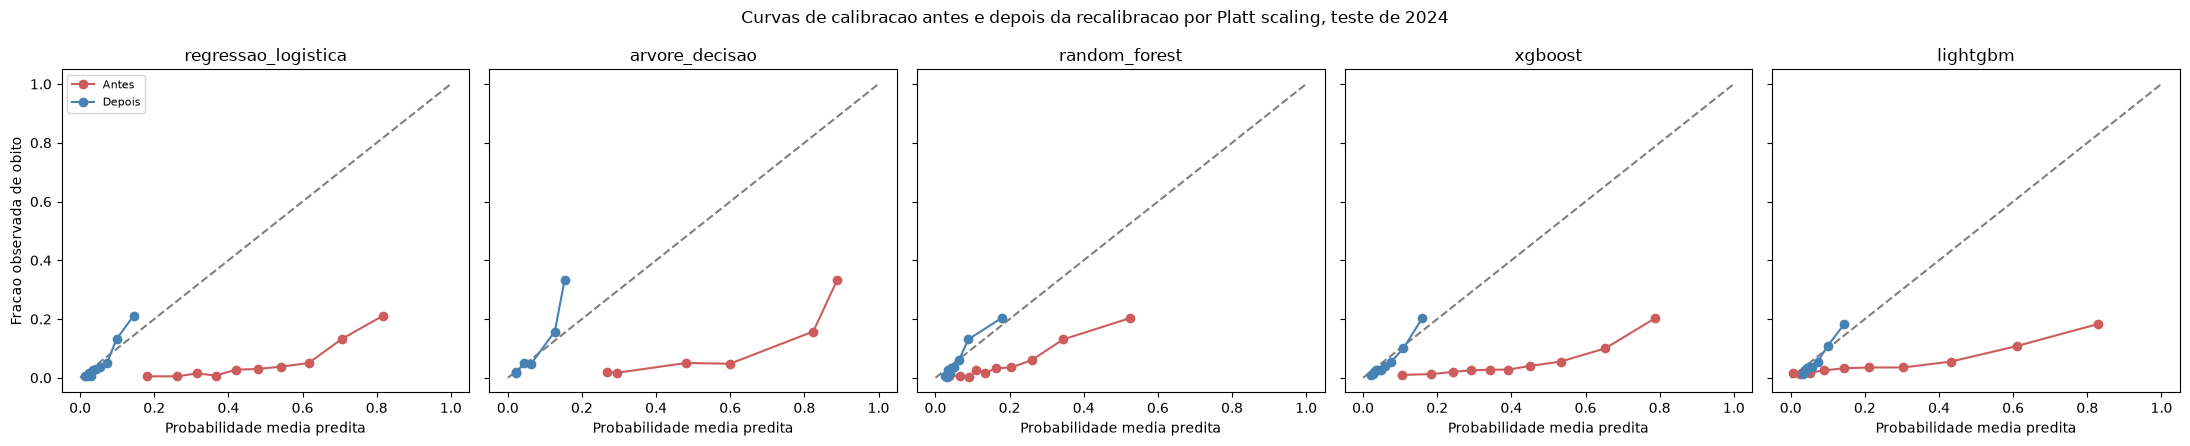

In [12]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(22, 4.5), sharex=True, sharey=True)

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    probabilidade_antes = predicoes_teste2024[algoritmo]["probabilidade_predita"].to_numpy()
    probabilidade_depois = predicoes_teste2024_calibrado[algoritmo]["probabilidade_predita"].to_numpy()

    fracao_observada_antes, probabilidade_media_antes = calibration_curve(
        alvo_real_teste2024, probabilidade_antes, n_bins=NUMERO_DECIS, strategy="quantile"
    )
    fracao_observada_depois, probabilidade_media_depois = calibration_curve(
        alvo_real_teste2024, probabilidade_depois, n_bins=NUMERO_DECIS, strategy="quantile"
    )

    eixo_atual.plot([0, 1], [0, 1], linestyle="--", color="gray")
    eixo_atual.plot(probabilidade_media_antes, fracao_observada_antes, marker="o", color="indianred", label="Antes")
    eixo_atual.plot(probabilidade_media_depois, fracao_observada_depois, marker="o", color="steelblue", label="Depois")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Probabilidade media predita")

eixos[0].set_ylabel("Fracao observada de obito")
eixos[0].legend(loc="upper left", fontsize=8)
figura.suptitle("Curvas de calibracao antes e depois da recalibracao por Platt scaling, teste de 2024")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "curvas_calibracao_antes_depois_recalibracao.png", dpi=150)
plt.show()

## Conclusao da recalibracao por Platt scaling

A recalibracao por Platt scaling melhora de forma substancial a qualidade absoluta das probabilidades preditas no teste de 2024, sem alterar a capacidade de ordenacao de risco dos cinco algoritmos.
Como a funcao de correcao e uma regressao logistica unidimensional, ou seja, uma transformacao estritamente crescente da probabilidade bruta, a AUPRC e o ROC-AUC calculados com as probabilidades recalibradas sao identicos, ate a precisao numerica, aos valores calculados com as probabilidades brutas, para os cinco algoritmos, tanto no teste de 2024 quanto na validacao externa de 2025.
Isso confirma que a correcao atua apenas sobre o nivel absoluto das probabilidades, e nao sobre a ordem relativa dos casos, exatamente como pretendido.

No teste de 2024, o Brier Skill Score deixa de ser negativo para todos os cinco algoritmos apos a recalibracao, passando de valores entre -0,466 para o Random Forest e -3,830 para a Regressao Logistica, antes da recalibracao, para valores entre 0,043 para a Arvore de Decisao e 0,073 para a Regressao Logistica, depois da recalibracao.
A Regressao Logistica passa a ter o melhor Brier Skill Score calibrado entre os cinco algoritmos, superando ligeiramente o Random Forest, 0,070, o que mostra que o deslocamento sistematico causado por `class_weight="balanced"`, a pior calibracao bruta entre os cinco antes da correcao por uma margem minima sobre a Arvore de Decisao, e corrigido de forma tao completa pela correcao sigmoide que a Regressao Logistica passa a lideranca do grupo.
O XGBoost tem Brier Skill Score calibrado de 0,061, numa posicao intermediaria, enquanto o LightGBM, 0,049, e a Arvore de Decisao, 0,043, ficam com os valores calibrados mais baixos do grupo, ainda que todos os cinco permanecam positivos e, portanto, melhores do que a referencia trivial depois da correcao.

Na validacao externa de 2025, ano que nao participa nem do treino do modelo final nem do ajuste da regressao logistica de calibracao, o Brier Skill Score tambem melhora de forma expressiva para os cinco algoritmos, de valores entre -1,264 para o Random Forest e -8,117 para a Regressao Logistica, antes da recalibracao, para valores entre -0,003 para o LightGBM e 0,028 para a Regressao Logistica, depois da recalibracao.
A Regressao Logistica tem o maior Brier Skill Score calibrado na validacao de 2025, com folga sobre os demais algoritmos, o que indica que a correcao aprendida em 2023 generaliza particularmente bem para esse algoritmo, ainda mais notavel porque a Regressao Logistica tinha o Brier Skill Score bruto mais negativo entre os cinco antes da recalibracao, tanto no teste de 2024 quanto na validacao de 2025.
O Random Forest, 0,021, e a Arvore de Decisao, 0,016, tambem mantem Brier Skill Score calibrado claramente positivo na validacao de 2025, enquanto o XGBoost fica com um valor calibrado praticamente nulo, 0,0002, ainda assim positivo, e o LightGBM e o unico dos cinco algoritmos com Brier Skill Score calibrado levemente negativo nesse ano, -0,003, uma leve queda de generalizacao da funcao de correcao esperada ao sair do ano de calibracao para um ano totalmente novo, mas que ainda assim representa uma melhora expressiva em relacao ao Brier Skill Score bruto desse mesmo algoritmo antes da recalibracao.

Em conjunto, estes resultados confirmam que a calibracao sigmoide e adequada para este estudo, no qual a reserva de calibracao disponivel, o ano de 2023, e pequena e o desfecho de obito e raro, cerca de 109 casos entre 2441.
A correcao sigmoide estima apenas dois parametros, a inclinacao e o intercepto da regressao logistica unidimensional, o que a torna estavel mesmo com uma reserva de calibracao pequena, sem introduzir empates artificiais entre casos de risco distinto e sem degradar a AUPRC ou o ROC-AUC de nenhum dos cinco algoritmos.
A partir deste notebook, os artefatos com o sufixo _calibrado em output/metricas/ e output/modelos/ sao a estimativa recomendada de risco real de obito para qualquer uso futuro do estudo que dependa do valor absoluto da probabilidade predita, enquanto os artefatos sem esse sufixo permanecem validos para qualquer analise baseada apenas na ordenacao dos casos por risco.